In [1]:
import socket, os

hostname = socket.gethostname()
if "scg" in hostname:
    BASE_DIR = "/labs/mwinslow/Karen/protein-master/v2_pancan_batch_corrected"
else:
    BASE_DIR = os.path.expanduser("~/Documents/research/scg/protein-master/v2_pancan_batch_corrected")

WORKING_DIR=f"{BASE_DIR}/analysis/03_complex"

os.chdir(WORKING_DIR)
print(f"📂 Working directory set to: {WORKING_DIR}")

📂 Working directory set to: /Users/karenshih/Documents/research/scg/protein-master/v2_pancan_batch_corrected/analysis/03_complex


In [2]:
import pandas as pd

In [3]:
df = pd.read_csv(f"{WORKING_DIR}/complex_axis_score_non_pqc.csv")

In [4]:
df_long = df.melt(
    id_vars=["cancer_type", "log_mut", "barcode"],
    value_vars=[
        "ribosome_biogenesis_in_eukaryotes",
        "spliceosome",
        "dna_replication",
        "cell_cycle",
        "oxidative_phosphorylation",
        "antigen_processing_and_presentation"
    ],
    var_name="complex",
    value_name="score"
)

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import pearsonr
from statsmodels.stats.multitest import fdrcorrection

def bootstrap_global_corr(df_long, n_boot=1000, seed=2026):

    np.random.seed(seed)
    results = []

    for complex_name, df_c in df_long.groupby("complex"):

        df_c = df_c.dropna(subset=["score", "log_mut"])

        # observed correlation
        r_obs = pearsonr(df_c["score"], df_c["log_mut"])[0]

        boot_rs = []

        for _ in range(n_boot):

            resampled_list = []

            for cancer, df_sub in df_c.groupby("cancer_type"):

                if len(df_sub) < 5:
                    continue

                sample = df_sub.sample(n=len(df_sub), replace=True)
                resampled_list.append(sample)

            df_boot = pd.concat(resampled_list, axis=0)

            try:
                r = pearsonr(df_boot["score"], df_boot["log_mut"])[0]
                boot_rs.append(r)
            except:
                continue

        boot_rs = np.array(boot_rs)

        # CI
        ci_low = np.percentile(boot_rs, 2.5)
        ci_high = np.percentile(boot_rs, 97.5)

        # --- empirical p-value ---
        p_lower = np.mean(boot_rs <= 0)
        p_upper = np.mean(boot_rs > 0)
        p_boot = 2 * min(p_lower, p_upper)

        # avoid exactly 0 (finite sampling)
        # p_boot = max(p_boot, 1 / n_boot)

        results.append({
            "complex": complex_name,
            "r": r_obs,
            "ci_low": ci_low,
            "ci_high": ci_high,
            "p_boot": p_boot,
            "n_samples": len(df_c)
        })
        
    result_df = pd.DataFrame(results)
    _, result_df["fdr"] = fdrcorrection(result_df["p_boot"])
    
    return pd.DataFrame(results)

In [ ]:
corr_boot_df = bootstrap_global_corr(df_long, n_boot=1000)

In [ ]:
corr_boot_df

In [ ]:
name_map = {
    "cell_cycle": "Cell cycle",
    "dna_replication": "DNA replication",
    "ribosome_biogenesis_in_eukaryotes": "Ribosome biogenesis in eukaryotes",
    "spliceosome": "Spliceosome",
    "antigen_processing_and_presentation": "Antigen processing and presentation",
    "oxidative_phosphorylation": "Oxidative phosphorylation"
}

corr_boot_df["complex_clean"] = corr_boot_df["complex"].map(name_map)

In [29]:
category_map = {
    "Cell cycle": "Cell growth and death",
    "DNA replication": "DNA replication and repair",
    "Ribosome biogenesis in eukaryotes": "Translation",
    "Spliceosome": "Transcription",
    "Antigen processing and presentation": "Immune",
    "Oxidative phosphorylation": "Metabolism"
}

corr_boot_df["category"] = corr_boot_df["complex_clean"].map(category_map)

In [ ]:
# corr_boot_df.to_csv(f"{BASE_DIR}/results/tables/non_pqc_correlation_summary.csv", index=None)


In [5]:
corr_boot_df = pd.read_csv(f"{BASE_DIR}/results/tables/fig1/non_pqc_correlation_summary.csv",)

In [6]:
corr_boot_df

,complex,r,ci_low,ci_high,p_boot,n_samples,complex_clean,category
0,antigen_processing_and_presentation,0.276170,0.257584,0.296289,0.0,9104,Antigen processing and presentation,Immune
1,cell_cycle,0.476987,0.465222,0.489162,0.0,9104,Cell cycle,Cell growth and death
2,dna_replication,0.428633,0.415147,0.441970,0.0,9104,DNA replication,DNA replication and repair
3,oxidative_phosphorylation,0.185778,0.167481,0.202928,0.0,9104,Oxidative phosphorylation,Metabolism
4,ribosome_biogenesis_in_eukaryotes,0.424787,0.411859,0.439226,0.0,9104,Ribosome biogenesis in eukaryotes,Translation
5,spliceosome,0.328232,0.312612,0.343203,0.0,9104,Spliceosome,Transcription


In [11]:
from statsmodels.stats.multitest import fdrcorrection

In [12]:
corr_boot_df["fdr"] = fdrcorrection(corr_boot_df["p_boot"])[1]

In [13]:
corr_boot_df

,complex,r,ci_low,ci_high,p_boot,n_samples,complex_clean,category,fdr
0,antigen_processing_and_presentation,0.276170,0.257584,0.296289,0.0,9104,Antigen processing and presentation,Immune,0.0
1,cell_cycle,0.476987,0.465222,0.489162,0.0,9104,Cell cycle,Cell growth and death,0.0
2,dna_replication,0.428633,0.415147,0.441970,0.0,9104,DNA replication,DNA replication and repair,0.0
3,oxidative_phosphorylation,0.185778,0.167481,0.202928,0.0,9104,Oxidative phosphorylation,Metabolism,0.0
4,ribosome_biogenesis_in_eukaryotes,0.424787,0.411859,0.439226,0.0,9104,Ribosome biogenesis in eukaryotes,Translation,0.0
5,spliceosome,0.328232,0.312612,0.343203,0.0,9104,Spliceosome,Transcription,0.0


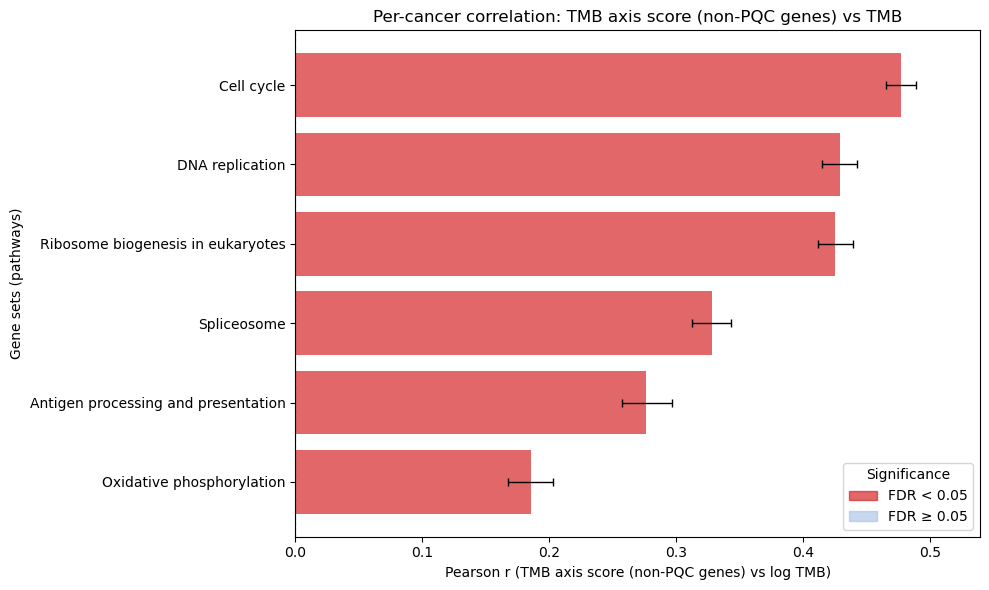

In [ ]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt

corr_df_sorted = corr_boot_df.sort_values("r")

fig, ax = plt.subplots(figsize=(10,6))

colors = ["#d62728" if p < 0.05 else "#aec7e8" for p in corr_df_sorted["fdr"]]

ax.barh(corr_df_sorted["complex_clean"], corr_df_sorted["r"], color=colors, alpha=0.7)
ax.errorbar(
    x=corr_df_sorted["r"],
    y=corr_df_sorted["complex_clean"],
    xerr=[
        corr_df_sorted["r"] - corr_df_sorted["ci_low"],
        corr_df_sorted["ci_high"] - corr_df_sorted["r"]
    ],
    fmt="none",
    color="black",
    capsize=3,
    linewidth=1
)

ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_xlabel("Pearson r (TMB axis score (non-PQC genes) vs log TMB)")
ax.set_ylabel("Gene sets (pathways)")
ax.set_title("Per-cancer correlation: TMB axis score (non-PQC genes) vs TMB")

legend_handles = [
    mpatches.Patch(color="#d62728", alpha=0.7, label="FDR < 0.05"),
    mpatches.Patch(color="#aec7e8", alpha=0.7, label="FDR ≥ 0.05"),
]
ax.legend(handles=legend_handles, title="Significance", loc="lower right")

xmin = corr_df_sorted["ci_low"].min()
xmax = corr_df_sorted["ci_high"].max()

pad = 0.05
ax.set_xlim(0, xmax + pad)

plt.tight_layout()
#plt.savefig(f"{BASE_DIR}/results/figures/main/fig1/non_pqc_correlation_summary.pdf", dpi=300)
plt.show()

In [17]:
xmax + pad

0.5391618537423553